# 1D $\mathbb{Z}_2$ lattice gauge theory: string breaking and confinement dynamics

Qiskit Aer の statevector simulator を用いて、staggered fermion を持つ 1 次元 $\mathbb{Z}_2$ lattice gauge theory の実時間発展を計算する。

arXiv:2206.00685 の同じ模型を、次の二つの量子ビット表現で実装する。

1. **staggered fermion + gauge fields** — Eqs. (6), (8), (9)
2. **gauge fields only** — Gauss 則で matter を除去した Eqs. (35), (36)

$L$ sites の開境界系に対し、前者は $2L-1$ qubits、後者は $L-1$ qubits を使う。両方式で Hamiltonian、charge sector、初期状態、物理量の定義を共通にする。

$$
E_n=\frac{1-Z_g(n)}2,\qquad N_n=\frac{1-Z_m(n)}2.
$$

偶数 site の $N_n$ を particle、奇数 site の $1-N_n$ を antiparticle excitation とする。さらに string survival と charge-pair number を計算する。

## Parameters

- `string_links`: `external_string=False` で電束を置く link 区間
- `external_string=True`: 全 link を $Z_g=-1$ にする境界間 string。`string_links` は使わない
- `external_string=False`: confinement dynamics 用の動的 meson
- `h/J`: electric energy と hopping の比
- `m/J`: particle--antiparticle pair の生成コスト
- `dt`: Trotter step。誤差を見る場合は同じ終時刻を保って小さくする

statevector memory は full staggered formulation で $2^{2L-1}$、gauge-only formulation で $2^{L-1}$ に比例する。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli
from qiskit_aer import AerSimulator

backend = AerSimulator(method="statevector")

## Common circuit functions and initial states

`external_string=True` では全 link を $Z_g=-1$ にし、matter は Dirac sea のままにする。ストリングの両端は系の境界 sites であり、外部電荷は staggered 背景 sector との差として現れる。この場合 `string_links` は使わず、観測対象も全 link とする。`external_string=False` では指定した `string_links` の電束の両端で occupation を反転し、外部電荷を持たない particle--antiparticle meson を作る。

charge sector は

$$
Z_g(n-1)Z_g(n)=(-1)^{N_n+q_n},\qquad \epsilon_n=(-1)^{q_n}
$$

で指定する。境界では $Z_g(-1)=Z_g(L-1)=1$ とする。

In [2]:
def pauli_rotation(qc, qubits, paulis, theta):
    for qubit, pauli in zip(qubits, paulis):
        if pauli == "X":
            qc.h(qubit)
        elif pauli == "Y":
            qc.sdg(qubit)
            qc.h(qubit)

    target = qubits[-1]
    for control in qubits[:-1]:
        qc.cx(control, target)
    qc.rz(2 * theta, target)
    for control in reversed(qubits[:-1]):
        qc.cx(control, target)

    for qubit, pauli in reversed(list(zip(qubits, paulis))):
        if pauli == "X":
            qc.h(qubit)
        elif pauli == "Y":
            qc.h(qubit)
            qc.s(qubit)


def expectation(state, n_qubits, operators):
    label = ["I"] * n_qubits
    for qubit, pauli in operators:
        label[n_qubits - 1 - qubit] = pauli
    return float(np.real(state.expectation_value(Pauli("".join(label)))))


def string_breaking_probability(state, string_links):
    # All selected link qubits must be |1> for the original string to be intact.
    intact_probability = state.probabilities(qargs=list(string_links))[-1]
    return float(1 - intact_probability)


def simulate(qc):
    compiled = transpile(qc, backend, optimization_level=1)
    return backend.run(compiled).result().data(0)


def initial_configuration(n_sites, string_links, external_string):
    link_field = np.ones(n_sites - 1, dtype=int)
    if external_string:
        link_field[:] = -1
    else:
        link_field[string_links] = -1

    gauss_field = np.ones(n_sites, dtype=int)
    gauss_field[0] = link_field[0]
    gauss_field[-1] = link_field[-1]
    gauss_field[1:-1] = link_field[:-1] * link_field[1:]

    dirac_sea = np.arange(n_sites) % 2
    if external_string:
        occupation = dirac_sea
        epsilon = (1 - 2 * occupation) * gauss_field
    else:
        epsilon = (-1) ** np.arange(n_sites)
        occupation = (1 - epsilon * gauss_field) // 2

    return link_field, occupation.astype(int), epsilon.astype(int)

## Method 1: staggered fermion and gauge fields

matter qubit $m_n$ を各 site、gauge qubit $g_n$ を各 link に置く。Jordan--Wigner 変換後の Hamiltonian は、定数項を除いて

$$
H_E=-h\sum_{n=0}^{L-2}Z_{g_n},
$$

$$
H_m=-\frac{m}{2}\sum_{n=0}^{L-1}(-1)^nZ_{m_n},
$$

$$
H_{GM}=-\frac{J}{2}\sum_{n=0}^{L-2}X_{g_n}
\left(X_{m_n}X_{m_{n+1}}+Y_{m_n}Y_{m_{n+1}}\right).
$$

対称 Trotter step $e^{-i(H_E+H_m)\Delta t/2}e^{-iH_{GM}\Delta t}e^{-i(H_E+H_m)\Delta t/2}$ を使う。

In [3]:
def staggered_diagonal_step(qc, n_sites, h, m, dt):
    n_links = n_sites - 1
    for link in range(n_links):
        pauli_rotation(qc, [link], "Z", -h * dt)
    for site in range(n_sites):
        matter_qubit = n_links + site
        pauli_rotation(qc, [matter_qubit], "Z", -m * (-1) ** site * dt / 2)


def staggered_interaction_step(qc, n_sites, J, dt):
    n_links = n_sites - 1
    for link in range(n_links):
        left_matter = n_links + link
        right_matter = left_matter + 1
        pauli_rotation(
            qc, [link, left_matter, right_matter], "XXX", -J * dt / 2
        )
        pauli_rotation(
            qc, [link, left_matter, right_matter], "XYY", -J * dt / 2
        )


def run_staggered_dynamics(
    n_sites, h, J, m, dt, steps, string_links, external_string
):
    n_links = n_sites - 1
    if external_string:
        string_links = list(range(n_links))
    n_qubits = 2 * n_sites - 1
    link_field, occupation_0, epsilon = initial_configuration(
        n_sites, string_links, external_string
    )

    qc = QuantumCircuit(n_qubits)
    for link in np.flatnonzero(link_field == -1):
        qc.x(link)
    for site in np.flatnonzero(occupation_0 == 1):
        qc.x(n_links + site)
    qc.save_statevector(label="t_0")

    for step in range(1, steps + 1):
        staggered_diagonal_step(qc, n_sites, h, m, dt / 2)
        staggered_interaction_step(qc, n_sites, J, dt)
        staggered_diagonal_step(qc, n_sites, h, m, dt / 2)
        qc.save_statevector(label=f"t_{step}")

    data = simulate(qc)
    electric = np.zeros((steps + 1, n_links))
    occupation = np.zeros((steps + 1, n_sites))
    breaking_probability = np.zeros(steps + 1)

    for step in range(steps + 1):
        state = data[f"t_{step}"]
        breaking_probability[step] = string_breaking_probability(state, string_links)
        for link in range(n_links):
            electric[step, link] = (
                1 - expectation(state, n_qubits, [(link, "Z")])
            ) / 2
        for site in range(n_sites):
            occupation[step, site] = (
                1 - expectation(state, n_qubits, [(n_links + site, "Z")])
            ) / 2

    matter = occupation.copy()
    matter[:, 1::2] = 1 - matter[:, 1::2]
    return {
        "time": dt * np.arange(steps + 1),
        "electric": electric,
        "occupation": occupation,
        "matter": matter,
        "charge": matter * ((-1) ** np.arange(n_sites))[None, :],
        "string": electric[:, string_links].mean(axis=1),
        "string_breaking_prob": breaking_probability,
        "pairs": matter.sum(axis=1) / 2,
        "epsilon": epsilon,
        "string_links": list(string_links),
        "circuit": qc,
    }

## Method 2: gauge fields only

Gauss 則から matter occupation を

$$
N_n=\frac{1-\epsilon_n Z_g(n-1)Z_g(n)}2
$$

と解き、matter qubits を除去する。mass term は arXiv:2206.00685 Eq. (35) の開境界版

$$
\widetilde H_m^{(2)}=-\frac m2\sum_{n=0}^{L-1}
(-1)^n\epsilon_n Z_g(n-1)Z_g(n),
$$

$$
\widetilde H_{GM}^{(2)}=-\frac J2\sum_{n=0}^{L-2}
X_{g_n}\left[1-\epsilon_n\epsilon_{n+1}Z_g(n-1)Z_g(n+1)\right].
$$

と書ける。相互作用の $X$ 項同士、および $XZZ$ 項同士はそれぞれ可換なので、相互作用 step は全 link の $X$ 半 step、全 link の $XZZ$、全 link の $X$ 半 step の順に適用する。$XZZ$ 層は隣接 link 間の $CZ$ の積 $U$ を用いた $U X U^\dagger$ として実装し、$CZ$ は偶数辺と奇数辺の2層に配置する。これは full Hamiltonian を Gauss-law sector に射影した一般 charge-sector の形である。論文が用いる $\epsilon_n=(-1)^n$ sector では $1+Z_g(n-1)Z_g(n+1)$ となり、局所 phase rotation により Eq. (36) の $Y$ 表現へ移る。したがって Dirac-sea sector の meson だけでなく、内部に静的外部 charge を持つ electric string も同じコードで扱える。

In [4]:
def gauge_only_diagonal_step(qc, n_sites, h, m, epsilon, dt):
    n_links = n_sites - 1
    for link in range(n_links):
        pauli_rotation(qc, [link], "Z", -h * dt)

    for site in range(n_sites):
        qubits = []
        paulis = ""
        if site > 0:
            qubits.append(site - 1)
            paulis += "Z"
        if site < n_links:
            qubits.append(site)
            paulis += "Z"
        coefficient = -m * (-1) ** site * epsilon[site] / 2
        pauli_rotation(qc, qubits, paulis, coefficient * dt)


def gauge_only_interaction_step(qc, n_sites, J, epsilon, dt):
    n_links = n_sites - 1
    # Strang split H_X + H_XZZ; every term within each layer commutes.
    for link in range(n_links):
        qc.rx(-J * dt / 2, link)

    # U X_link U = Z_(link-1) X_link Z_(link+1), where U is the
    # product of CZ gates on neighboring links. Even/odd edges give
    # two parallel CZ layers, independent of the chain length.
    for parity in (0, 1):
        for edge in range(parity, n_links - 1, 2):
            qc.cz(edge, edge + 1)
    for link in range(n_links):
        qc.rx(J * epsilon[link] * epsilon[link + 1] * dt, link)
    for parity in (0, 1):
        for edge in range(parity, n_links - 1, 2):
            qc.cz(edge, edge + 1)

    for link in range(n_links):
        qc.rx(-J * dt / 2, link)


def run_gauge_only_dynamics(
    n_sites, h, J, m, dt, steps, string_links, external_string
):
    n_links = n_sites - 1
    if external_string:
        string_links = list(range(n_links))
    link_field, occupation_0, epsilon = initial_configuration(
        n_sites, string_links, external_string
    )

    qc = QuantumCircuit(n_links)
    for link in np.flatnonzero(link_field == -1):
        qc.x(link)
    qc.save_statevector(label="t_0")

    for step in range(1, steps + 1):
        gauge_only_diagonal_step(qc, n_sites, h, m, epsilon, dt / 2)
        gauge_only_interaction_step(qc, n_sites, J, epsilon, dt)
        gauge_only_diagonal_step(qc, n_sites, h, m, epsilon, dt / 2)
        qc.save_statevector(label=f"t_{step}")

    data = simulate(qc)
    electric = np.zeros((steps + 1, n_links))
    occupation = np.zeros((steps + 1, n_sites))
    breaking_probability = np.zeros(steps + 1)

    for step in range(steps + 1):
        state = data[f"t_{step}"]
        breaking_probability[step] = string_breaking_probability(state, string_links)
        link_z = np.array([
            expectation(state, n_links, [(link, "Z")])
            for link in range(n_links)
        ])
        electric[step] = (1 - link_z) / 2
        gauss_field = np.ones(n_sites)
        gauss_field[0] = link_z[0]
        gauss_field[-1] = link_z[-1]
        for site in range(1, n_sites - 1):
            gauss_field[site] = expectation(
                state, n_links, [(site - 1, "Z"), (site, "Z")]
            )
        occupation[step] = (1 - epsilon * gauss_field) / 2

    matter = occupation.copy()
    matter[:, 1::2] = 1 - matter[:, 1::2]
    return {
        "time": dt * np.arange(steps + 1),
        "electric": electric,
        "occupation": occupation,
        "matter": matter,
        "charge": matter * ((-1) ** np.arange(n_sites))[None, :],
        "string": electric[:, string_links].mean(axis=1),
        "string_breaking_prob": breaking_probability,
        "pairs": matter.sum(axis=1) / 2,
        "epsilon": epsilon,
        "string_links": list(string_links),
        "circuit": qc,
    }

## String breaking dynamics

matter を Dirac sea に置いたまま全 link を $Z_g=-1$ にする。外部電荷は、staggered 背景 sector と比べて両端 sites に置かれる。

$h$ は単位長さあたりの string energy、$m$ は動的 charge の生成コストを制御する。$h/J=0.3$ を固定し、重い matter と massless matter を比較する。

初期 string の全 link が同時に電束ありである確率の補数を
$P_{\rm break}(t)=1-\left\langle\prod_{\ell\in\mathcal I}(1-Z_{g_\ell})/2\right\rangle_t$
と定義する。これは各 link の平均電束 $S_{\rm string}(t)$ とは異なる。


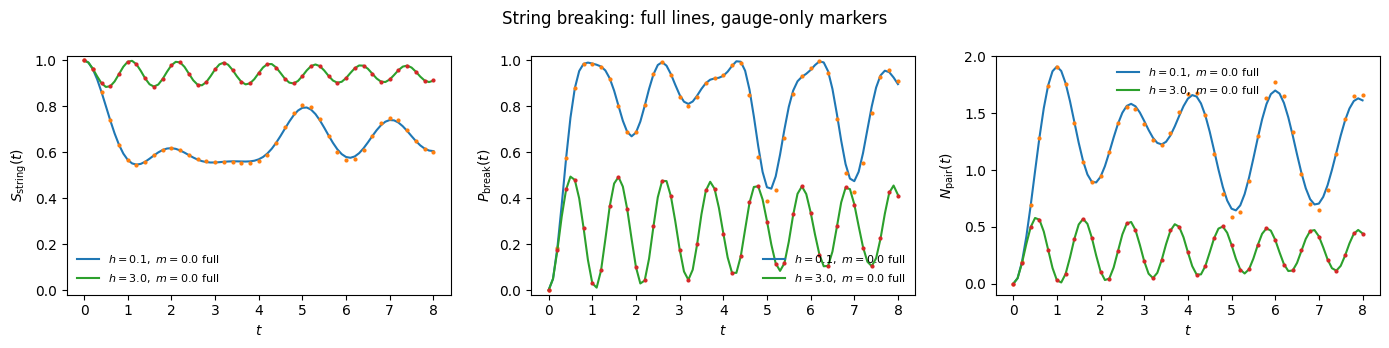

In [ ]:
n_sites = 6
J = 1.0
dt = 0.10
steps = 80
string_links = list(range(n_sites - 1))

string_parameters = {
    r"$h=0.1,\ m=0.0$": (0.1, 0.0),
    r"$h=3.0,\ m=0.0$": (3.0, 0.0),
}

string_breaking = {}
for label, (h, m) in string_parameters.items():
    string_breaking[label] = {
        "staggered": run_staggered_dynamics(
            n_sites, h, J, m, dt, steps, string_links, external_string=True
        ),
        "gauge_only": run_gauge_only_dynamics(
            n_sites, h, J, m, dt, steps, string_links, external_string=True
        ),
    }

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for label, results in string_breaking.items():
    full = results["staggered"]
    reduced = results["gauge_only"]
    axes[0].plot(full["time"], full["string"], label=label + " full")
    axes[0].plot(reduced["time"], reduced["string"], "o", ms=2, markevery=2)
    axes[1].plot(full["time"], full["string_breaking_prob"], label=label + " full")
    axes[1].plot(reduced["time"], reduced["string_breaking_prob"], "o", ms=2, markevery=2)
    axes[2].plot(full["time"], full["pairs"], label=label + " full")
    axes[2].plot(reduced["time"], reduced["pairs"], "o", ms=2, markevery=2)
axes[0].set(xlabel=r"$t$", ylabel=r"$S_{\rm string}(t)$", ylim=(-0.02, 1.02))
axes[1].set(xlabel=r"$t$", ylabel=r"$P_{\rm break}(t)$", ylim=(-0.02, 1.02))
axes[2].set(xlabel=r"$t$", ylabel=r"$N_{\rm pair}(t)$")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("String breaking: full lines, gauge-only markers")
fig.tight_layout()
plt.show()

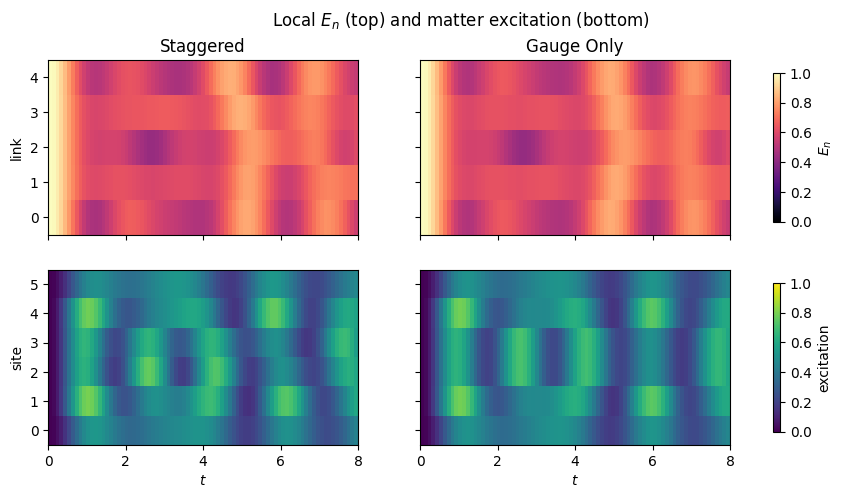

In [12]:
representation_comparison = string_breaking[rf"$h=0.1,\ m=0.0$"]
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey="row")

for column, (name, result) in enumerate(representation_comparison.items()):
    assert np.allclose(result["electric"][0], 1), (
        "External string must start with Z_g=-1 on every link; rerun the definition and string_breaking cells."
    )
    electric_image = axes[0, column].imshow(
        result["electric"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="magma",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 1.5],
    )
    matter_image = axes[1, column].imshow(
        result["matter"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="viridis",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 0.5],
    )
    axes[0, column].set_title(name.replace("_", " ").title())
    axes[1, column].set_xlabel(r"$t$")
axes[0, 0].set_ylabel("link")
axes[1, 0].set_ylabel("site")
fig.colorbar(electric_image, ax=axes[0, :], label=r"$E_n$", shrink=0.85)
fig.colorbar(matter_image, ax=axes[1, :], label="excitation", shrink=0.85)
fig.suptitle(r"Local $E_n$ (top) and matter excitation (bottom)")
plt.show()

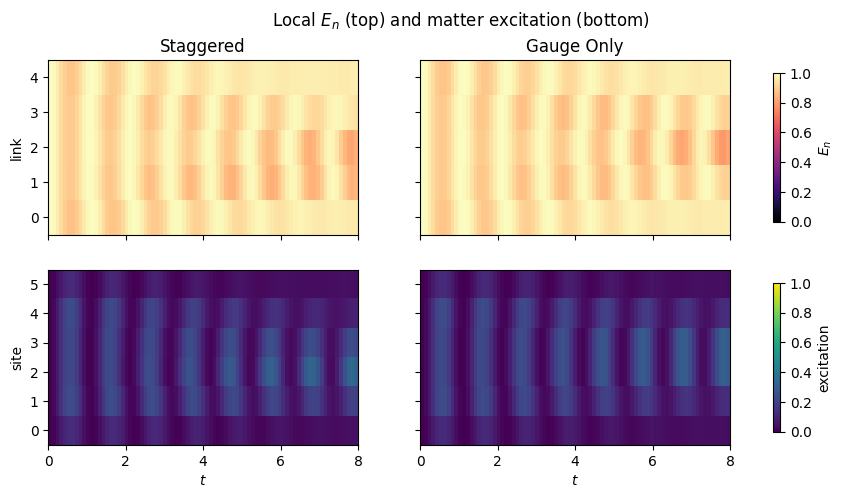

In [13]:
representation_comparison = string_breaking[rf"$h=3.0,\ m=0.0$"]
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey="row")

for column, (name, result) in enumerate(representation_comparison.items()):
    assert np.allclose(result["electric"][0], 1), (
        "External string must start with Z_g=-1 on every link; rerun the definition and string_breaking cells."
    )
    electric_image = axes[0, column].imshow(
        result["electric"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="magma",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 1.5],
    )
    matter_image = axes[1, column].imshow(
        result["matter"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="viridis",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 0.5],
    )
    axes[0, column].set_title(name.replace("_", " ").title())
    axes[1, column].set_xlabel(r"$t$")
axes[0, 0].set_ylabel("link")
axes[1, 0].set_ylabel("site")
fig.colorbar(electric_image, ax=axes[0, :], label=r"$E_n$", shrink=0.85)
fig.colorbar(matter_image, ax=axes[1, :], label="excitation", shrink=0.85)
fig.suptitle(r"Local $E_n$ (top) and matter excitation (bottom)")
plt.show()

## Confinement dynamics

Dirac-sea sector の中央 link とその両端の matter occupation を反転し、外部 charge のない gauge-invariant meson を作る。arXiv:2206.00685 Fig. 4 と同様に、小さい $h/J$ と大きい $h/J$ を比較する。

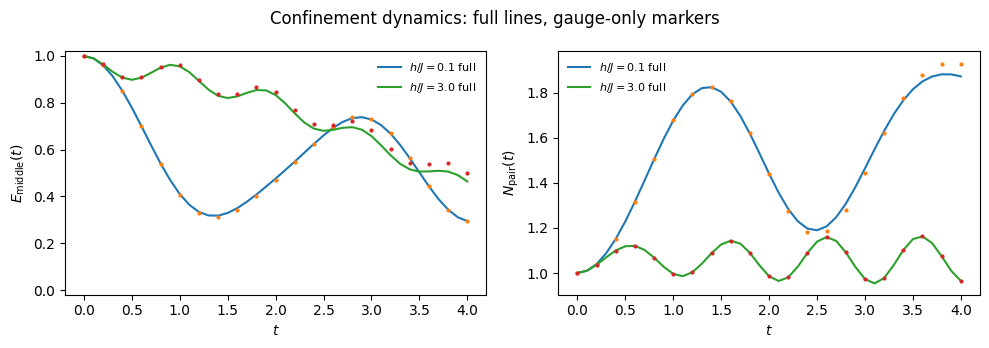

In [8]:
middle_link = (n_sites - 2) // 2
confinement_steps = 40
confinement_parameters = {
    r"$h/J=0.1$": 0.1,
    r"$h/J=3.0$": 3.0,
}

confinement = {}
for label, h in confinement_parameters.items():
    confinement[label] = {
        "staggered": run_staggered_dynamics(
            n_sites, h, J, 0.0, dt, confinement_steps, [middle_link], external_string=False
        ),
        "gauge_only": run_gauge_only_dynamics(
            n_sites, h, J, 0.0, dt, confinement_steps, [middle_link], external_string=False
        ),
    }

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, results in confinement.items():
    full = results["staggered"]
    reduced = results["gauge_only"]
    axes[0].plot(full["time"], full["string"], label=label + " full")
    axes[0].plot(reduced["time"], reduced["string"], "o", ms=2, markevery=2)
    axes[1].plot(full["time"], full["pairs"], label=label + " full")
    axes[1].plot(reduced["time"], reduced["pairs"], "o", ms=2, markevery=2)
axes[0].set(xlabel=r"$t$", ylabel=r"$E_{\rm middle}(t)$", ylim=(-0.02, 1.02))
axes[1].set(xlabel=r"$t$", ylabel=r"$N_{\rm pair}(t)$")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Confinement dynamics: full lines, gauge-only markers")
fig.tight_layout()
plt.show()

## Local observables in both representations

二つの `run_*_dynamics` は全く同じ keys を返す。以下では $E_n$ と particle/antiparticle excitation の時空分布を同じ color scale で並べる。


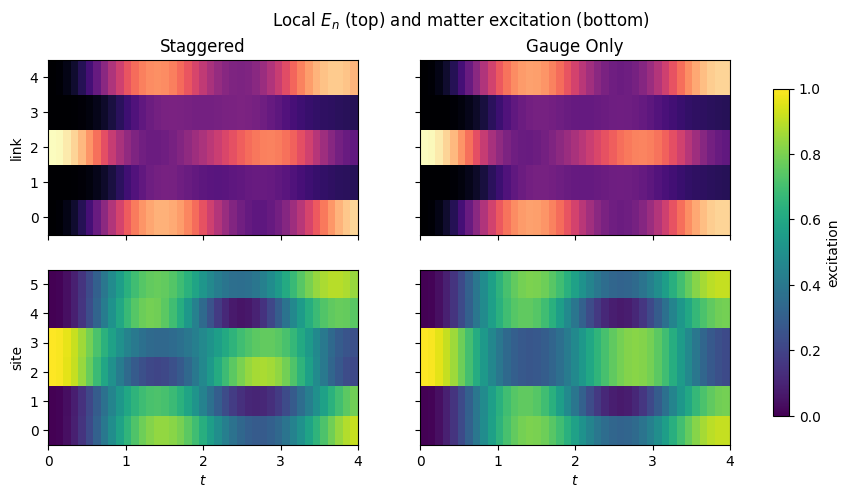

In [9]:
representation_comparison = confinement[r"$h/J=0.1$"]
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey="row")

for column, (name, result) in enumerate(representation_comparison.items()):
    axes[0, column].imshow(
        result["electric"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="magma",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 1.5],
    )
    image = axes[1, column].imshow(
        result["matter"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="viridis",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 0.5],
    )
    axes[0, column].set_title(name.replace("_", " ").title())
    axes[1, column].set_xlabel(r"$t$")
axes[0, 0].set_ylabel("link")
axes[1, 0].set_ylabel("site")
fig.colorbar(image, ax=axes, label="excitation", shrink=0.85)
fig.suptitle(r"Local $E_n$ (top) and matter excitation (bottom)")
plt.show()


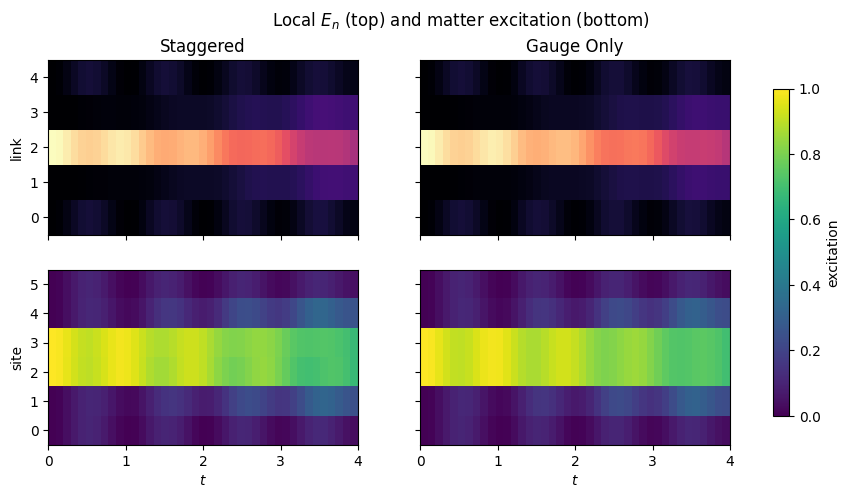

In [10]:
representation_comparison = confinement[r"$h/J=3.0$"]
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey="row")

for column, (name, result) in enumerate(representation_comparison.items()):
    axes[0, column].imshow(
        result["electric"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="magma",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 1.5],
    )
    image = axes[1, column].imshow(
        result["matter"].T,
        origin="lower", aspect="auto", vmin=0, vmax=1, cmap="viridis",
        extent=[result["time"][0], result["time"][-1], -0.5, n_sites - 0.5],
    )
    axes[0, column].set_title(name.replace("_", " ").title())
    axes[1, column].set_xlabel(r"$t$")
axes[0, 0].set_ylabel("link")
axes[1, 0].set_ylabel("site")
fig.colorbar(image, ax=axes, label="excitation", shrink=0.85)
fig.suptitle(r"Local $E_n$ (top) and matter excitation (bottom)")
plt.show()


## Rényi entropy across the initial meson

第2 Rényi エントロピー $S_2(A)=-\log_2\mathrm{Tr}(\rho_A^2)$ を3通りで計算する。分割は初期メソンの位置に固定する。

1. **Full:** 内側 $A$ は中央 gauge link と両端の matter sites。
2. **Gauge-only:** 内側 $A$ は中央 gauge link のみ。
3. **Gauge-only + matter:** 各電束配置に Gauss 則 $N_n=(1-\epsilon_n Z_{g_{n-1}}Z_{g_n})/2$ で matter をコヒーレントに復元し、1と同じ $A$ で計算する。

2は異なる分割のエントロピーであり、1と一致する必要はない。1と3は同じ分割を測る。厳密な時間発展では一致し、このノートブックの有限 Trotter step では差が残り得る。


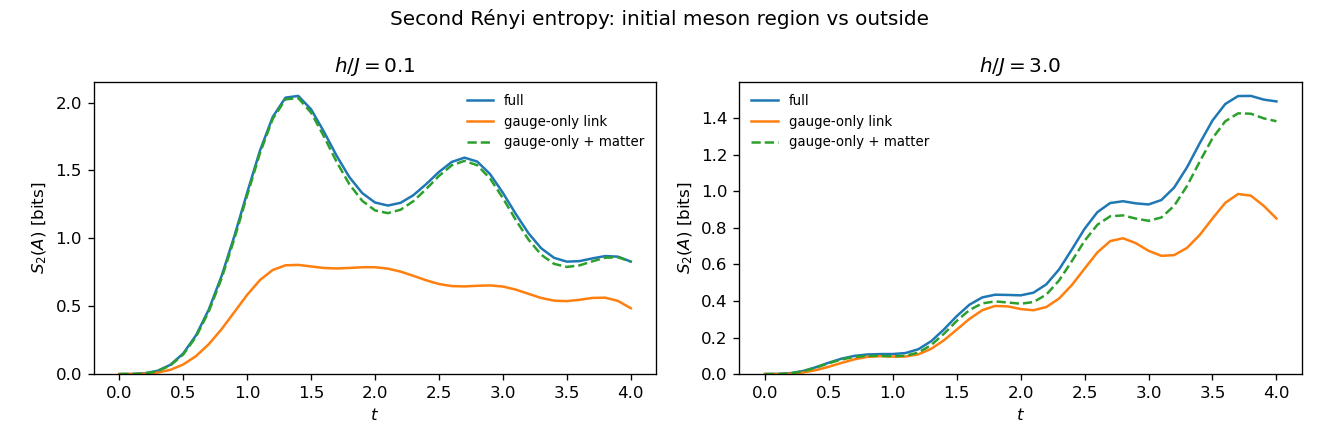

In [9]:
from qiskit.quantum_info import Statevector, partial_trace


def restore_matter(state, epsilon):
    n_links = state.num_qubits
    n_sites = n_links + 1
    restored = np.zeros(1 << (n_links + n_sites), dtype=complex)
    for gauge_bits, amplitude in enumerate(state.data):
        link_z = 1 - 2 * np.array(
            [(gauge_bits >> link) & 1 for link in range(n_links)], dtype=int
        )
        gauss = np.ones(n_sites, dtype=int)
        gauss[0], gauss[-1] = link_z[0], link_z[-1]
        gauss[1:-1] = link_z[:-1] * link_z[1:]
        occupation = (1 - epsilon * gauss) // 2
        matter_bits = sum(int(value) << site for site, value in enumerate(occupation))
        restored[gauge_bits | (matter_bits << n_links)] = amplitude
    return Statevector(restored)


def second_renyi(state, inside):
    outside = [qubit for qubit in range(state.num_qubits) if qubit not in inside]
    purity = float(np.real(partial_trace(state, outside).purity()))
    return -np.log2(np.clip(purity, 1e-15, 1.0))


n_links = n_sites - 1
inside_full = [middle_link, n_links + middle_link, n_links + middle_link + 1]
inside_gauge_only = [middle_link]
renyi2_by_h = {}
fig, axes = plt.subplots(1, len(confinement), figsize=(11, 3.7), squeeze=False)
axes = axes[0]

for axis, (label, results) in zip(axes, confinement.items()):
    full = results["staggered"]
    gauge_only = results["gauge_only"]
    full_snapshots = simulate(full["circuit"])
    gauge_snapshots = simulate(gauge_only["circuit"])
    curves = {
        "staggered": np.zeros(len(full["time"])),
        "gauge_only": np.zeros(len(full["time"])),
        "reconstructed": np.zeros(len(full["time"])),
    }
    for step in range(len(full["time"])):
        full_state = full_snapshots[f"t_{step}"]
        gauge_state = gauge_snapshots[f"t_{step}"]
        restored_state = restore_matter(gauge_state, gauge_only["epsilon"])
        curves["staggered"][step] = second_renyi(full_state, inside_full)
        curves["gauge_only"][step] = second_renyi(gauge_state, inside_gauge_only)
        curves["reconstructed"][step] = second_renyi(restored_state, inside_full)
    renyi2_by_h[label] = curves
    axis.plot(full["time"], curves["staggered"], label="full")
    axis.plot(full["time"], curves["gauge_only"], label="gauge-only link")
    axis.plot(full["time"], curves["reconstructed"], "--", label="gauge-only + matter")
    axis.set(xlabel=r"$t$", ylabel=r"$S_2(A)$ [bits]", title=label)
    axis.set_ylim(bottom=0)
    axis.legend(frameon=False, fontsize=8)
fig.suptitle("Second Rényi entropy: initial meson region vs outside")
fig.tight_layout()
plt.show()


### **問**

day1にならって量子回路と測定を構成し、statevector計算を再現してみよ. 

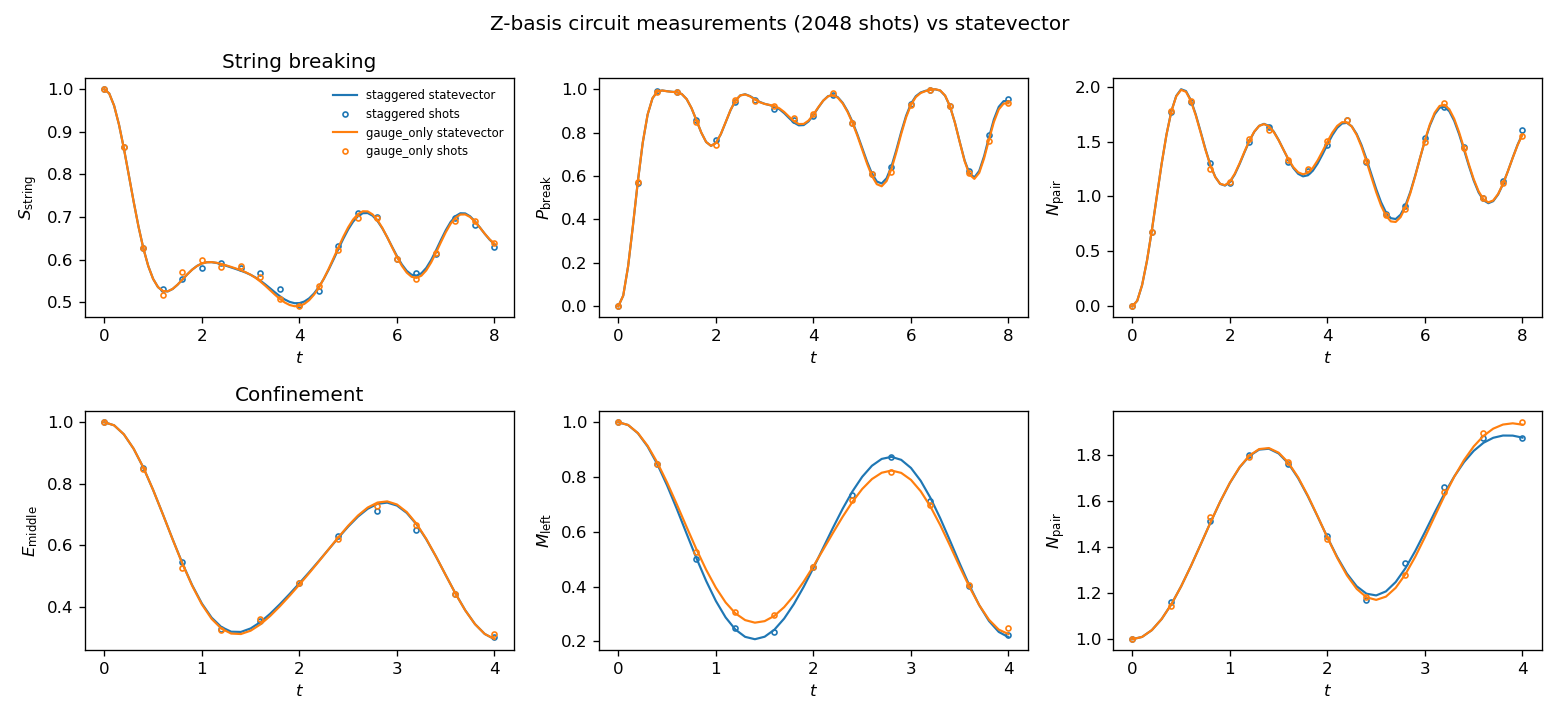

In [10]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

# Measurement parameters (adjust here when changing shot precision or time resolution).
shots = 2048
measurement_stride = 4
measurement_seed = 2026
measurement_backend = AerSimulator(method="matrix_product_state", seed_simulator=measurement_seed)


def build_evolution_circuit(
    n_sites, h, J, m, dt, steps, string_links, external_string, representation
):
    """Build the same Trotter evolution directly, without snapshot instructions."""
    n_links = n_sites - 1
    link_field, occupation_0, epsilon = initial_configuration(
        n_sites, string_links, external_string
    )
    n_qubits = 2 * n_sites - 1 if representation == "staggered" else n_links
    circuit = QuantumCircuit(n_qubits)
    for link in np.flatnonzero(link_field == -1):
        circuit.x(link)
    if representation == "staggered":
        for site in np.flatnonzero(occupation_0 == 1):
            circuit.x(n_links + site)
    elif representation != "gauge_only":
        raise ValueError(f"Unknown representation: {representation}")

    for _ in range(steps):
        if representation == "staggered":
            staggered_diagonal_step(circuit, n_sites, h, m, dt / 2)
            staggered_interaction_step(circuit, n_sites, J, dt)
            staggered_diagonal_step(circuit, n_sites, h, m, dt / 2)
        else:
            gauge_only_diagonal_step(circuit, n_sites, h, m, epsilon, dt / 2)
            gauge_only_interaction_step(circuit, n_sites, J, epsilon, dt)
            gauge_only_diagonal_step(circuit, n_sites, h, m, epsilon, dt / 2)
    return circuit


def build_measurement_circuits(
    n_sites, h, J, m, dt, steps, string_links, external_string,
    representation, sample_every=1,
):
    """Return hardware-ready Z-measurement circuits at selected times."""
    sampled_steps = list(range(0, steps + 1, sample_every))
    if sampled_steps[-1] != steps:
        sampled_steps.append(steps)
    circuits = []
    for step in sampled_steps:
        circuit = build_evolution_circuit(
            n_sites, h, J, m, dt, step, string_links, external_string, representation
        )
        circuit.measure_all()
        circuits.append(circuit)
    return sampled_steps, circuits


def run_sampler_circuits(circuits, backend, shots):
    """Run the same measured circuits on Aer or an IBM Quantum backend."""
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuits = pass_manager.run(circuits)
    result = SamplerV2(mode=backend).run(isa_circuits, shots=shots).result()
    return [
        getattr(result[index].data, circuit.cregs[0].name).get_counts()
        for index, circuit in enumerate(circuits)
    ]


def sample_evolution(
    n_sites, h, J, m, dt, steps, string_links, external_string,
    representation, shots, sample_every=1, seed=2026, backend=None,
):
    sampled_steps, circuits = build_measurement_circuits(
        n_sites, h, J, m, dt, steps, string_links, external_string,
        representation, sample_every,
    )
    if backend is None:
        backend = AerSimulator(method="matrix_product_state", seed_simulator=seed)
    return sampled_steps, run_sampler_circuits(circuits, backend, shots)


def observables_from_counts(counts, n_sites, epsilon, string_links, representation):
    """Estimate the diagonal observables from the joint Z-basis distribution."""
    n_links = n_sites - 1
    electric = np.zeros(n_links)
    occupation = np.zeros(n_sites)
    intact = 0
    total = sum(counts.values())
    for bitstring, count in counts.items():
        bits = int(bitstring.replace(" ", ""), 2)
        links = np.array([(bits >> link) & 1 for link in range(n_links)], dtype=int)
        if representation == "staggered":
            matter_bits = np.array(
                [(bits >> (n_links + site)) & 1 for site in range(n_sites)],
                dtype=int,
            )
        elif representation == "gauge_only":
            link_z = 1 - 2 * links
            gauss = np.ones(n_sites, dtype=int)
            gauss[0], gauss[-1] = link_z[0], link_z[-1]
            gauss[1:-1] = link_z[:-1] * link_z[1:]
            matter_bits = (1 - epsilon * gauss) // 2
        else:
            raise ValueError(f"Unknown representation: {representation}")
        electric += count * links
        occupation += count * matter_bits
        if all(links[link] == 1 for link in string_links):
            intact += count
    electric /= total
    occupation /= total
    matter = occupation.copy()
    matter[1::2] = 1 - matter[1::2]
    return {
        "electric": electric,
        "occupation": occupation,
        "matter": matter,
        "string": electric[string_links].mean(),
        "string_breaking_prob": 1 - intact / total,
        "pairs": matter.sum() / 2,
    }


def measure_dynamics(
    statevector_result, n_sites, h, J, m, dt, external_string,
    representation, shots, stride, seed, backend=None,
):
    total_steps = len(statevector_result["time"]) - 1
    steps, count_series = sample_evolution(
        n_sites, h, J, m, dt, total_steps, statevector_result["string_links"],
        external_string, representation, shots, stride, seed, backend,
    )
    estimates = [
        observables_from_counts(
            counts, n_sites, statevector_result["epsilon"],
            statevector_result["string_links"], representation,
        )
        for counts in count_series
    ]
    result = {"time": statevector_result["time"][steps], "shots": shots}
    for key in ("electric", "occupation", "matter", "string", "string_breaking_prob", "pairs"):
        result[key] = np.array([item[key] for item in estimates])
    return result


# A case from each dynamics section; both qubit representations use the
# identical evolution circuits and differ only in how matter is read out.
measurement_cases = {
    "String breaking": string_breaking[r"$h=0.3,\ m=0.0$"],
    "Confinement": confinement[r"$h/J=0.1$"],
}
measurement_parameters = {
    "String breaking": (0.3, 0.0, True),
    "Confinement": (0.1, 0.0, False),
}
measured_dynamics = {}
for case_name, representations in measurement_cases.items():
    h, m, external_string = measurement_parameters[case_name]
    measured_dynamics[case_name] = {}
    for representation, exact in representations.items():
        measured_dynamics[case_name][representation] = measure_dynamics(
            exact, n_sites, h, J, m, dt, external_string, representation,
            shots, measurement_stride, measurement_seed, measurement_backend,
        )

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex="row")
for row, (case_name, representations) in enumerate(measurement_cases.items()):
    for representation, exact in representations.items():
        sampled = measured_dynamics[case_name][representation]
        for column in range(3):
            if case_name == "String breaking":
                key = ("string", "string_breaking_prob", "pairs")[column]
                ylabel = (r"$S_{\rm string}$", r"$P_{\rm break}$", r"$N_{\rm pair}$")[column]
                exact_y, sampled_y = exact[key], sampled[key]
            else:
                key = ("electric", "matter", "pairs")[column]
                ylabel = (r"$E_{\rm middle}$", r"$M_{\rm left}$", r"$N_{\rm pair}$")[column]
                exact_y = exact[key][:, middle_link] if column < 2 else exact[key]
                sampled_y = sampled[key][:, middle_link] if column < 2 else sampled[key]
            color = "tab:blue" if representation == "staggered" else "tab:orange"
            axes[row, column].plot(exact["time"], exact_y, color=color, lw=1.3,
                                   label=representation + " statevector")
            axes[row, column].plot(sampled["time"], sampled_y, "o", color=color,
                                   ms=3, fillstyle="none", label=representation + " shots")
            axes[row, column].set(xlabel=r"$t$", ylabel=ylabel)
    axes[row, 0].set_title(case_name)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle(f"Z-basis circuit measurements ({shots} shots) vs statevector")
fig.tight_layout()
plt.show()


### Rényi エントロピーの測定

$S_2(A)$ は1回の $Z$ 基底測定だけでは求められない。各時刻の状態を2コピー用意し、領域 $A$ の対応する量子ビット対に Bell 基底測定（CNOT、Hadamard、$Z$ 測定）を行う。これは補助量子ビットと controlled-SWAP を使わない **destructive SWAP test** で、測定後の2コピーは破壊される。各対の結果が $11$ のときだけその対の SWAP 固有値は $-1$、それ以外は $+1$ である。全対の固有値の積をショット平均すると $\mathrm{Tr}(\rho_A^2)$ になる。gauge-only + matter の場合は、Gauss 則に従う matter ancilla を CNOT でコヒーレントに付けてから、full と同じ領域を測る。有限ショットのため推定値には統計誤差がある。


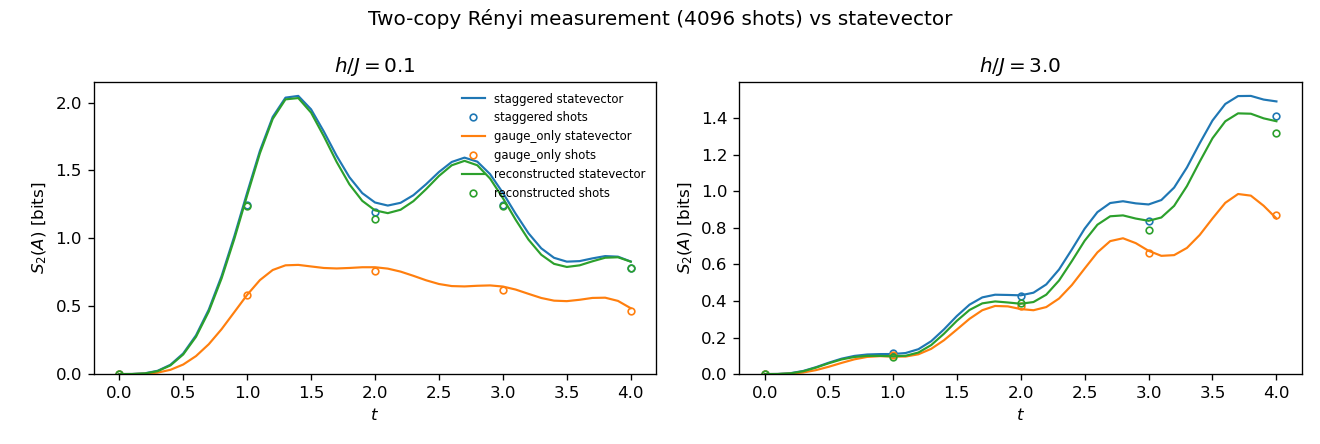

In [11]:
# Two-copy entropy measurement parameters.
renyi_shots = 4096
renyi_measurement_stride = 10


def restore_matter_circuit(gauge_circuit, epsilon):
    """Coherently implement |g>|0...0> -> |g>|N(g)> from Gauss law."""
    n_links = gauge_circuit.num_qubits
    n_sites = n_links + 1
    full = QuantumCircuit(n_links + n_sites)
    full.compose(gauge_circuit, qubits=range(n_links), inplace=True)
    for site in range(n_sites):
        target = n_links + site
        if epsilon[site] == -1:
            full.x(target)
        if site > 0:
            full.cx(site - 1, target)
        if site < n_links:
            full.cx(site, target)
    return full


def build_renyi_measurement_circuit(preparation, inside):
    """Return a hardware-ready two-copy Bell measurement of the SWAP on A."""
    n_qubits = preparation.num_qubits
    circuit = QuantumCircuit(2 * n_qubits, 2 * len(inside))
    circuit.compose(preparation, qubits=range(n_qubits), inplace=True)
    circuit.compose(preparation, qubits=range(n_qubits, 2 * n_qubits), inplace=True)
    for pair, qubit in enumerate(inside):
        circuit.cx(qubit, n_qubits + qubit)
        circuit.h(qubit)
        circuit.measure(qubit, 2 * pair)
        circuit.measure(n_qubits + qubit, 2 * pair + 1)
    return circuit


def measure_second_renyi(preparation, inside, shots, seed, backend=None):
    """Estimate S2 from the two-copy measured circuit's parity counts."""
    circuit = build_renyi_measurement_circuit(preparation, inside)
    if backend is None:
        backend = AerSimulator(method="matrix_product_state", seed_simulator=seed)
    counts = run_sampler_circuits([circuit], backend, shots)[0]
    purity = 0.0
    for bitstring, count in counts.items():
        bits = int(bitstring.replace(" ", ""), 2)
        antisymmetric_pairs = sum(
            (bits >> (2 * pair) & 1) * (bits >> (2 * pair + 1) & 1)
            for pair in range(len(inside))
        )
        purity += (-1) ** antisymmetric_pairs * count / shots
    return -np.log2(np.clip(purity, 1e-12, 1.0))


renyi_sample_steps = list(range(0, confinement_steps + 1, renyi_measurement_stride))
if renyi_sample_steps[-1] != confinement_steps:
    renyi_sample_steps.append(confinement_steps)
measured_renyi2 = {}
for label, representations in confinement.items():
    h = confinement_parameters[label]
    gauge = representations["gauge_only"]
    curves = {name: [] for name in ("staggered", "gauge_only", "reconstructed")}
    for step in renyi_sample_steps:
        full_prefix = build_evolution_circuit(
            n_sites, h, J, 0.0, dt, step, [middle_link], False, "staggered"
        )
        gauge_prefix = build_evolution_circuit(
            n_sites, h, J, 0.0, dt, step, [middle_link], False, "gauge_only"
        )
        restored_prefix = restore_matter_circuit(gauge_prefix, gauge["epsilon"])
        for name, circuit, inside in (
            ("staggered", full_prefix, inside_full),
            ("gauge_only", gauge_prefix, inside_gauge_only),
            ("reconstructed", restored_prefix, inside_full),
        ):
            curves[name].append(measure_second_renyi(
                circuit, inside, renyi_shots, measurement_seed, measurement_backend
            ))
    measured_renyi2[label] = {name: np.array(values) for name, values in curves.items()}

fig, axes = plt.subplots(1, len(confinement), figsize=(11, 3.7), squeeze=False)
for axis, (label, representations) in zip(axes[0], confinement.items()):
    time = representations["staggered"]["time"]
    for name, color in (("staggered", "tab:blue"),
                        ("gauge_only", "tab:orange"),
                        ("reconstructed", "tab:green")):
        axis.plot(time, renyi2_by_h[label][name], color=color, lw=1.3,
                  label=name + " statevector")
        axis.plot(time[renyi_sample_steps], measured_renyi2[label][name],
                  "o", color=color, ms=4, fillstyle="none", label=name + " shots")
    axis.set(xlabel=r"$t$", ylabel=r"$S_2(A)$ [bits]", title=label)
    axis.set_ylim(bottom=0)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle(f"Two-copy Rényi measurement ({renyi_shots} shots) vs statevector")
fig.tight_layout()
plt.show()


### 実機での実行

上の `build_measurement_circuits` と `build_renyi_measurement_circuit` は、測定を含む通常の `QuantumCircuit` を返す。回路内に `save_statevector` や Aer 固有の命令はない。ノートブックの図は `measurement_backend = AerSimulator(...)` で作る。実機では、認証済みの IBM Quantum アカウントで以下を実行する。`run_sampler_circuits` は指定されたバックエンド向けに transpile し、`SamplerV2` から counts を取得する。実機のノイズと回路深さにより、測定値は理想的な statevector 結果からずれる。

```python
from qiskit_ibm_runtime import QiskitRuntimeService

step = 10
z_circuit = build_evolution_circuit(
    n_sites, 0.1, J, 0.0, dt, step, [middle_link], False, "staggered"
)
z_circuit.measure_all()

gauge_preparation = build_evolution_circuit(
    n_sites, 0.1, J, 0.0, dt, step, [middle_link], False, "gauge_only"
)
full_preparation = restore_matter_circuit(
    gauge_preparation, confinement[r"$h/J=0.1$"]["gauge_only"]["epsilon"]
)
renyi_circuit = build_renyi_measurement_circuit(full_preparation, inside_full)

service = QiskitRuntimeService()
qpu = service.least_busy(
    operational=True, simulator=False,
    min_num_qubits=max(z_circuit.num_qubits, renyi_circuit.num_qubits),
)
z_counts = run_sampler_circuits([z_circuit], qpu, shots)[0]
renyi_counts = run_sampler_circuits([renyi_circuit], qpu, renyi_shots)[0]
```
